# 01 Data audit

**Objective.** Confirm what is in the data pack and check every known quirk against the data before any rule is written.

**Inputs.** The six raw CSVs in data_prep/raw, never modified.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. File inventory and row counts

In [2]:
from data_prep.clean import load_raw
from data_prep import audit
raw = load_raw()
audit.inventory(raw)

,file,rows,columns,missing_cells_pct
0,ball_by_ball.csv,200999,33,11.555402
1,matches.csv,883,22,14.084217
2,competitions.csv,141,4,0.000000
3,teams.csv,353,3,0.000000
4,playing_eleven.csv,28381,9,10.183652
5,competition_team_player_mapping.csv,6413,6,0.000000


## Step 2. Column types and missingness, ball table

In [3]:
audit.column_profile(raw["ball_by_ball"])

,column,dtype,missing_pct,unique
0,match_id,int64,0.000000,867
1,innings,int64,0.000000,4
2,overid,int64,0.000000,20
3,over_ball_num,int64,0.000000,13
4,innings_ball_num,int64,0.000000,136
5,batting_team_id,int64,0.000000,38
6,bowling_team_id,int64,0.000000,38
7,striker_id,int64,0.000000,888
8,striker_name,str,0.000000,885
9,non_striker_id,int64,0.000000,867


## Step 3. Missingness by field and competition type

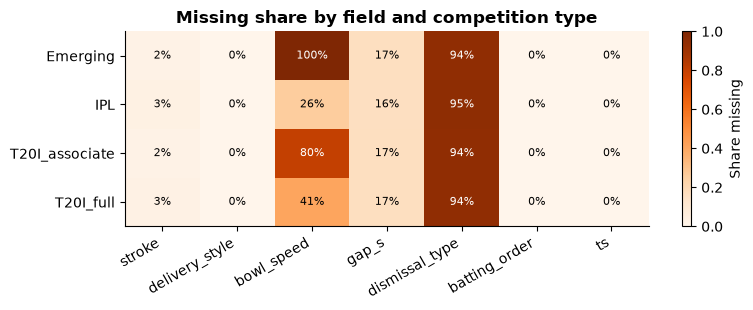

In [4]:
from data_prep import plots as p1
balls = read_parquet("data_prep", "balls_clean.parquet")
matches = read_parquet("data_prep", "matches_clean.parquet")
p1.missingness(balls); plt.show()

## Step 4. Categorical value counts

In [5]:
for col in ["extras_type", "dismissal_type", "pace_or_spin", "batting_type", "innings"]:
    display(raw["ball_by_ball"][col].value_counts(dropna=False).rename(col).to_frame().T)

extras_type,NaN,wide,legbyes,Overstep,byes,other,Penalty
extras_type,189167,7714,2748,576,529,264,1


dismissal_type,NaN,Caught,Bowled,LBW,RunOut,Stump,Hit Wicket,Retire Out,Obstracting the field,Obstructing the field
dismissal_type,190118,7557,1775,709,600,214,17,6,2,1


pace_or_spin,Pace,Spin
pace_or_spin,123886,77113


batting_type,RHB,LHB
batting_type,131006,69993


innings,1,2,3,4
innings,105727,95234,25,13


## Step 5. Data quirks, each with the number that confirms it

In [6]:
q = audit.quirk_checks(raw, balls, matches)
q

,quirk,check,value,note
0,Q1,T20 label competitions,7.000000,IPL 2022 to 2026 plus two emerging events
1,Q2,"Bat runs only in runs column, extras separate",0.000000,zero bat runs on wides
2,Q3,Max legal balls per innings with other treated...,120.000000,120 expected
3,Q3,Innings above 120 legal balls if other were legal,150.000000,other is a no-ball
4,Q3,Mean bat runs on other extras,1.560606,batter scores off it like a no-ball
5,Q4,Super over balls,38.000000,kept apart
6,Q5,Obstructing typo rows,2.000000,normalised
7,Q6,Run-outs of the non-striker,274.000000,charged by dismissed id
8,Q7,No result or abandoned matches,40.000000,dropped
9,Q7,Decided matches with revised overs or DLS,28.000000,"excluded in v1, revised overs columns are held..."


## Step 6. Matches by format, season and competition type

match_format
T20I    134
T20       7
Name: count, dtype: int64

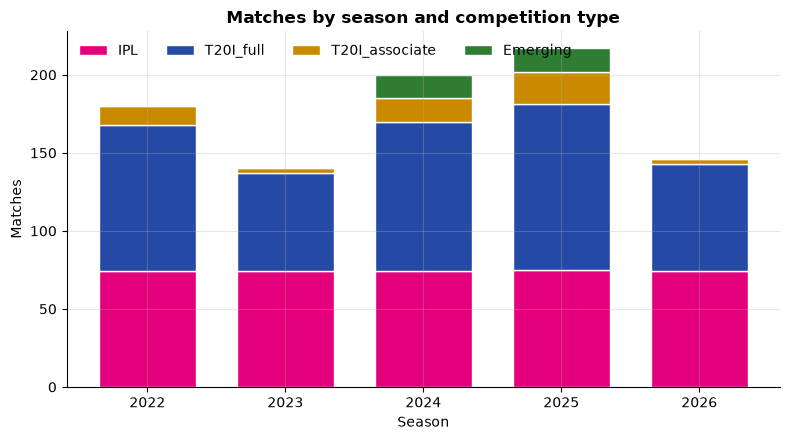

comp_type,season,Emerging,IPL,T20I_associate,T20I_full
0,2022,0,74,12,94
1,2023,0,74,3,63
2,2024,15,74,15,96
3,2025,15,75,21,106
4,2026,0,74,3,69


In [7]:
display(raw["competitions"]["match_format"].value_counts())
p1.matches_by_season(); plt.show()
audit.matches_by_season(matches)

## Step 7. Coverage of speed, stroke, delivery style and timestamps by competition type

In [8]:
audit.coverage_by_comp(balls)

,comp_type,balls,stroke,delivery_style,speed,gap
0,Emerging,6985,0.979671,0.998568,0.000000,0.833071
1,IPL,87687,0.966483,0.999886,0.741193,0.837273
2,T20I_associate,11950,0.977406,0.998996,0.196736,0.833640
3,T20I_full,94377,0.970258,0.996196,0.591182,0.832290


## Step 8. Timestamp validity

In [9]:
gap = balls["gap_s"]
print(f"valid gaps {gap.notna().mean():.1%}, median {gap.median():.0f}s, p10 {gap.quantile(.1):.0f}s, p90 {gap.quantile(.9):.0f}s")
balls["ts"].dt.strftime("%H:%M:%S").eq("00:00:00").mean()

valid gaps 83.5%, median 37s, p10 22s, p90 64s


np.float64(0.00020895626346399733)

## Key findings

In [10]:
q = q.set_index(["quirk", "check"])["value"]
display(Markdown(f'''
- {len(raw["ball_by_ball"]):,} deliveries, {raw["matches"].shape[0]} matches, {raw["competitions"].shape[0]} competitions.
- Treating extras type other as a no-ball caps legal balls at {q[("Q3", "Max legal balls per innings with other treated as no-ball")]:.0f} per innings, otherwise {q[("Q3", "Innings above 120 legal balls if other were legal")]:.0f} innings pass 120.
- {q[("Q7", "No result or abandoned matches")]:.0f} no-result matches and {q[("Q7", "Decided matches with revised overs or DLS")]:.0f} decided DLS or revised matches, {q[("Q7", "DLS results with no revised fields")]:.0f} of them only visible in the result text.
- {q[("Q11", "Names mapped to more than one ID")]:.0f} names map to two IDs each, kept apart, IDs are never merged.
- Associate bowling sides deliver {q[("Q14", "Associate bowling side share of T20I balls")]:.1%} of T20I balls.
- Median valid gap between balls {q[("Q9", "Median valid gap seconds")]:.0f} seconds.
'''))


- 200,999 deliveries, 883 matches, 141 competitions.
- Treating extras type other as a no-ball caps legal balls at 120 per innings, otherwise 150 innings pass 120.
- 40 no-result matches and 28 decided DLS or revised matches, 4 of them only visible in the result text.
- 3 names map to two IDs each, kept apart, IDs are never merged.
- Associate bowling sides deliver 7.2% of T20I balls.
- Median valid gap between balls 37 seconds.


## Outputs written

data_prep/output/tables, inventory.csv, quirk_checks.csv, coverage_by_comp.csv, matches_by_season.csv. Figures 01_missingness.png and 01_matches_by_season.png.